# 01 — QQQ Prototype: V&D Cloud, Phase 1

**Project:** Volatility & Dispersion (V&D) Cloud — personal research project
**Phase:** 1 — MVP prototype on QQQ
**Data:** public daily prices via `yfinance` only

**Research question.** Can a synthetic volatility-and-dispersion state variable, mapped through
an Ichimoku-style same-date cloud, produce market regime labels that say anything honest about
forward returns — for a single, concentrated large-cap index (QQQ)?

**Clean-room note.** This notebook uses public market data only (via `yfinance`). It does not
reference, rely on, or reproduce any proprietary employer systems, employer data, internal tools,
or internal methodology. It is an independently rebuilt personal research project.

**Curation note.** This notebook is a compressed, cleaned-up retelling of a much larger private
working notebook (~250 cells across many validation rounds). The logic here — components, signal
variants, cloud geometry, HAC inference, permutation testing — is the actual logic used in that
original build, not reinvented for this write-up. It has **not been re-executed** in this curation
pass; run `pip install -r requirements.txt` and execute top-to-bottom fresh before treating any
printed number as current.

**What this notebook does *not* do:** create trading rules, size positions, optimize parameters,
or claim predictive power. See the closing verdict at the end.

## 1. Data Ingestion

Pull adjusted close prices for QQQ (benchmark), TQQQ (3x leveraged overlay, used only as a
downstream forward-return comparison asset), and a fixed starter universe of large-cap constituents
used to compute cross-sectional dispersion.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

sys.path.insert(0, str(Path("..").resolve()))
import config

print(f"pandas  : {pd.__version__}")
print(f"numpy   : {np.__version__}")
print(f"yfinance: {yf.__version__}")

pandas  : 2.1.4
numpy   : 1.26.3
yfinance: 1.4.1


In [2]:
START_DATE       = config.START_DATE
END_DATE         = config.END_DATE
BENCHMARK_TICKER = config.BENCHMARK_TICKER
OVERLAY_TICKER   = config.OVERLAY_TICKER
Z_WINDOW         = config.Z_WINDOW
VOL_WINDOW       = config.VOL_WINDOW
SMOOTH_WINDOW    = config.SMOOTH_WINDOW
CONVERSION_WINDOW = config.CONVERSION_WINDOW
BASE_WINDOW       = config.BASE_WINDOW
SPAN_B_WINDOW     = config.SPAN_B_WINDOW
FORWARD_HORIZONS  = config.FORWARD_HORIZONS

# Fixed large-cap starter universe used only to compute cross-sectional dispersion.
# Hardcoded for MVP simplicity -- dynamic constituent tracking is out of scope for Phase 1.
STARTER_UNIVERSE = [
    "AAPL", "MSFT", "NVDA", "AMZN", "META", "GOOGL", "GOOG", "AVGO", "TSLA", "COST",
    "NFLX", "AMD", "ADBE", "CSCO", "PEP", "QCOM", "TXN", "INTU", "AMAT", "ISRG",
    "BKNG", "AMGN", "HON", "SBUX", "ADP", "MDLZ", "GILD", "LRCX", "MU", "PANW",
    "KLAC", "SNPS", "CDNS", "MAR", "ORLY", "REGN", "VRTX", "MELI", "ABNB", "CRWD",
]

print(f"Date range   : {START_DATE} to {END_DATE or 'latest'}")
print(f"Benchmark    : {BENCHMARK_TICKER}   Overlay: {OVERLAY_TICKER}")
print(f"Universe size: {len(STARTER_UNIVERSE)} tickers")
print(f"Z / vol / smooth windows: {Z_WINDOW} / {VOL_WINDOW} / {SMOOTH_WINDOW}")
print(f"Cloud windows (conversion/base/span-b): {CONVERSION_WINDOW} / {BASE_WINDOW} / {SPAN_B_WINDOW}")

Date range   : 2015-01-01 to 2026-05-30
Benchmark    : QQQ   Overlay: TQQQ
Universe size: 40 tickers
Z / vol / smooth windows: 126 / 21 / 5
Cloud windows (conversion/base/span-b): 9 / 26 / 52


In [3]:
all_tickers = list(dict.fromkeys(STARTER_UNIVERSE + [BENCHMARK_TICKER, OVERLAY_TICKER]))

raw = yf.download(tickers=all_tickers, start=START_DATE, end=END_DATE,
                   auto_adjust=True, progress=True)

# yfinance's column layout has changed across versions -- handle both
# (Price, Ticker) and (Ticker, Price) multi-index orderings, plus the
# single-ticker flat-column case.
if raw.columns.nlevels == 2:
    level_0 = raw.columns.get_level_values(0).unique().tolist()
    price_fields = {"Close", "Adj Close", "Open", "High", "Low", "Volume"}
    if level_0[0] in price_fields:
        close_field = "Close" if "Close" in level_0 else "Adj Close"
        prices = raw[close_field].copy()
    else:
        level_1 = raw.columns.get_level_values(1).unique().tolist()
        close_field = "Close" if "Close" in level_1 else "Adj Close"
        prices = raw.xs(close_field, axis=1, level=1).copy()
else:
    close_field = "Close" if "Close" in raw.columns else "Adj Close"
    prices = raw[[close_field]].copy()
    prices.columns = all_tickers[:1]

prices = prices.sort_index().dropna(how="all")
# No forward-fill: leave gaps in place so they're handled explicitly at the
# returns stage rather than silently treated as zero-return days.

print(f"Prices shape: {prices.shape}   field used: {close_field}")
print(f"Date range  : {prices.index[0].date()} to {prices.index[-1].date()}")

[                       0%                       ]

[**                     5%                       ]  2 of 42 completed

[***                    7%                       ]  3 of 42 completed

[***                    7%                       ]  3 of 42 completed

[*******               14%                       ]  6 of 42 completed

...

[**********************90%******************     ]  38 of 42 completed

[**********************93%********************   ]  39 of 42 completed

[**********************95%*********************  ]  40 of 42 completed

[*********************100%***********************]  42 of 42 completed

Prices shape: (2868, 42)   field used: Close
Date range  : 2015-01-02 to 2026-05-29


In [4]:
returns = prices.pct_change().dropna(how="all")

universe_cols = [t for t in STARTER_UNIVERSE if t in returns.columns]
universe_returns = returns[universe_cols].copy()
# Require at least 2 valid constituent returns per date for dispersion to be meaningful.
universe_returns = universe_returns[universe_returns.notna().sum(axis=1) >= 2]

benchmark_returns = returns[[BENCHMARK_TICKER]].squeeze().rename(BENCHMARK_TICKER)
overlay_returns   = returns[[OVERLAY_TICKER]].squeeze().rename(OVERLAY_TICKER)

print(f"returns shape          : {returns.shape}")
print(f"universe_returns shape : {universe_returns.shape}")
print(f"First valid return date: {returns.dropna(how='all').index[0].date()}")

returns shape          : (2867, 42)
universe_returns shape : (2867, 40)
First valid return date: 2015-01-05


## 2. Dispersion and Realized-Volatility Components

Two raw building blocks feed the signal:

- **Cross-sectional dispersion** — the standard deviation, across the starter universe, of each
  day's constituent returns. High dispersion means stocks are moving apart from each other.
- **QQQ realized volatility** — a rolling 21-day standard deviation of QQQ's own daily returns,
  annualized.

Both are plausibly correlated during stress regimes (market-wide moves widen dispersion *and*
raise realized vol at the same time). Whether they carry distinct information is a question for
later validation, not something to assume here.

components shape: (2847, 4)
Correlation (dispersion_daily vs realized_vol_daily): 0.2973


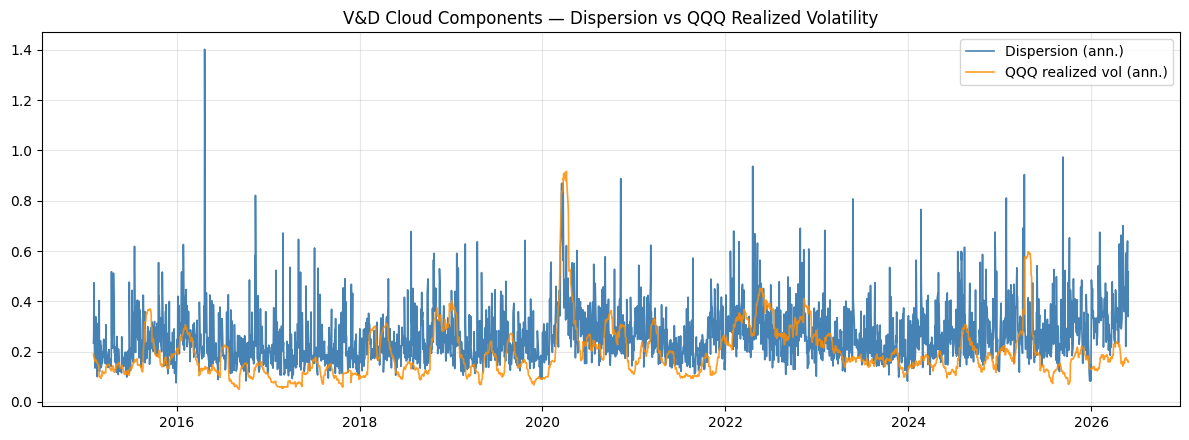

In [5]:
TRADING_DAYS = 252

valid_counts = universe_returns.count(axis=1)
dispersion_daily = universe_returns.std(axis=1, skipna=True).where(valid_counts >= 2)
dispersion_ann = dispersion_daily * np.sqrt(TRADING_DAYS)

realized_vol_daily = benchmark_returns.rolling(window=VOL_WINDOW).std()
realized_vol_ann = realized_vol_daily * np.sqrt(TRADING_DAYS)

components = pd.DataFrame({
    "dispersion_daily": dispersion_daily,
    "dispersion_ann": dispersion_ann,
    "realized_vol_daily": realized_vol_daily,
    "realized_vol_ann": realized_vol_ann,
}).dropna()

corr = components["dispersion_daily"].corr(components["realized_vol_daily"])
print(f"components shape: {components.shape}")
print(f"Correlation (dispersion_daily vs realized_vol_daily): {corr:.4f}")

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(components.index, components["dispersion_ann"], color="steelblue", linewidth=1.2, label="Dispersion (ann.)")
ax.plot(components.index, components["realized_vol_ann"], color="darkorange", linewidth=1.2, alpha=0.85, label="QQQ realized vol (ann.)")
ax.set_title("V&D Cloud Components — Dispersion vs QQQ Realized Volatility")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Note on correlation.** Dispersion and volatility may look correlated, particularly in stress
regimes when market-wide moves simultaneously widen cross-sectional spreads and elevate realized
volatility. Whether they add distinct information to the combined signal, or simply double-count
the same regime stress, is determined by the validation steps later in this notebook — it should
not be assumed from the correlation alone.

## 3. Rolling Z-Score Normalization

Both components are put on a common, comparable scale with a rolling Z-score
(`(x - rolling_mean) / rolling_std`, window = `Z_WINDOW` = 126 trading days, ≈ 6 months).

In [6]:
def rolling_zscore(series, window):
    rolling_mean = series.rolling(window=window).mean()
    rolling_std = series.rolling(window=window).std()
    return (series - rolling_mean) / rolling_std

dispersion_z = rolling_zscore(dispersion_daily, Z_WINDOW)
volatility_z = rolling_zscore(realized_vol_daily, Z_WINDOW)

print(f"dispersion_z valid obs: {dispersion_z.notna().sum()}  (first valid: {dispersion_z.first_valid_index().date()})")
print(f"volatility_z valid obs: {volatility_z.notna().sum()}  (first valid: {volatility_z.first_valid_index().date()})")

dispersion_z valid obs: 2742  (first valid: 2015-07-06)
volatility_z valid obs: 2722  (first valid: 2015-08-03)


## 4. Additive and Penalty Signal Variants

Two combinations of the normalized components, plus two single-component controls:

- **Additive** (`0.70 * dispersion_z + 0.30 * volatility_z`) — tests whether volatility amplifies
  opportunity alongside dispersion.
- **Penalty** (`0.70 * dispersion_z - 0.30 * volatility_z`) — tests whether volatility overwhelms
  signal clarity and should reduce the score instead.
- **Dispersion-only** / **volatility-only** — single-component baselines/controls.

None of these are assumed correct going in. Each is smoothed with a `SMOOTH_WINDOW` = 5-day
moving average before being fed into the cloud geometry below.

In [7]:
vd_additive_raw        = 0.70 * dispersion_z + 0.30 * volatility_z
vd_penalty_raw         = 0.70 * dispersion_z - 0.30 * volatility_z
vd_dispersion_only_raw = dispersion_z.copy()
vd_volatility_only_raw = volatility_z.copy()

vd_additive        = vd_additive_raw.rolling(window=SMOOTH_WINDOW).mean()
vd_penalty         = vd_penalty_raw.rolling(window=SMOOTH_WINDOW).mean()
vd_dispersion_only = vd_dispersion_only_raw.rolling(window=SMOOTH_WINDOW).mean()
vd_volatility_only = vd_volatility_only_raw.rolling(window=SMOOTH_WINDOW).mean()

signal_variants = {
    "additive": vd_additive,
    "penalty": vd_penalty,
    "dispersion_only": vd_dispersion_only,
    "volatility_only": vd_volatility_only,
}
for name, s in signal_variants.items():
    print(f"  {name:18s} valid obs: {s.notna().sum()}")

  additive           valid obs: 2718
  penalty            valid obs: 2718
  dispersion_only    valid obs: 2738
  volatility_only    valid obs: 2718


## 5. Same-Date Cloud Geometry and Regime Labels

An Ichimoku-style cloud, applied to the *signal* (not price): a fast rolling midpoint
(conversion line, 9-day), a medium rolling midpoint (base line, 26-day), and a slow rolling
midpoint (Span B, 52-day). Span A is the average of the conversion and base lines. The cloud band
is the row-wise max/min of Span A and Span B — all computed **same-date**, with no forward
shifting.

Each date is classified `above_cloud`, `inside_cloud`, or `below_cloud` depending on where the
signal sits relative to the band. This is built for both the additive and penalty lenses, since
the later validation steps compare the two.

In [8]:
def rolling_midpoint(series, window):
    rolling_high = series.rolling(window=window).max()
    rolling_low = series.rolling(window=window).min()
    return (rolling_high + rolling_low) / 2

def build_variant_cloud(signal, variant_name):
    conversion = rolling_midpoint(signal, CONVERSION_WINDOW)
    base       = rolling_midpoint(signal, BASE_WINDOW)
    span_a     = (conversion + base) / 2
    span_b     = rolling_midpoint(signal, SPAN_B_WINDOW)

    cloud_top    = pd.concat([span_a, span_b], axis=1).max(axis=1)
    cloud_bottom = pd.concat([span_a, span_b], axis=1).min(axis=1)

    regime = pd.Series(index=signal.index, dtype="object")
    regime = regime.mask(signal > cloud_top, "above_cloud")
    regime = regime.mask((signal <= cloud_top) & (signal >= cloud_bottom), "inside_cloud")
    regime = regime.mask(signal < cloud_bottom, "below_cloud")
    valid = signal.notna() & cloud_top.notna() & cloud_bottom.notna()
    regime = regime.where(valid)

    frame = pd.DataFrame({
        "signal": signal, "conversion_line": conversion, "base_line": base,
        "span_a": span_a, "span_b": span_b,
        "cloud_top": cloud_top, "cloud_bottom": cloud_bottom, "regime_state": regime,
    })
    return frame.dropna(subset=["signal", "cloud_top", "cloud_bottom", "regime_state"])

--- additive regime distribution ---
regime_state
below_cloud     1313
above_cloud      812
inside_cloud     568
Name: count, dtype: int64

--- penalty regime distribution ---
regime_state
below_cloud     1221
above_cloud      892
inside_cloud     580
Name: count, dtype: int64



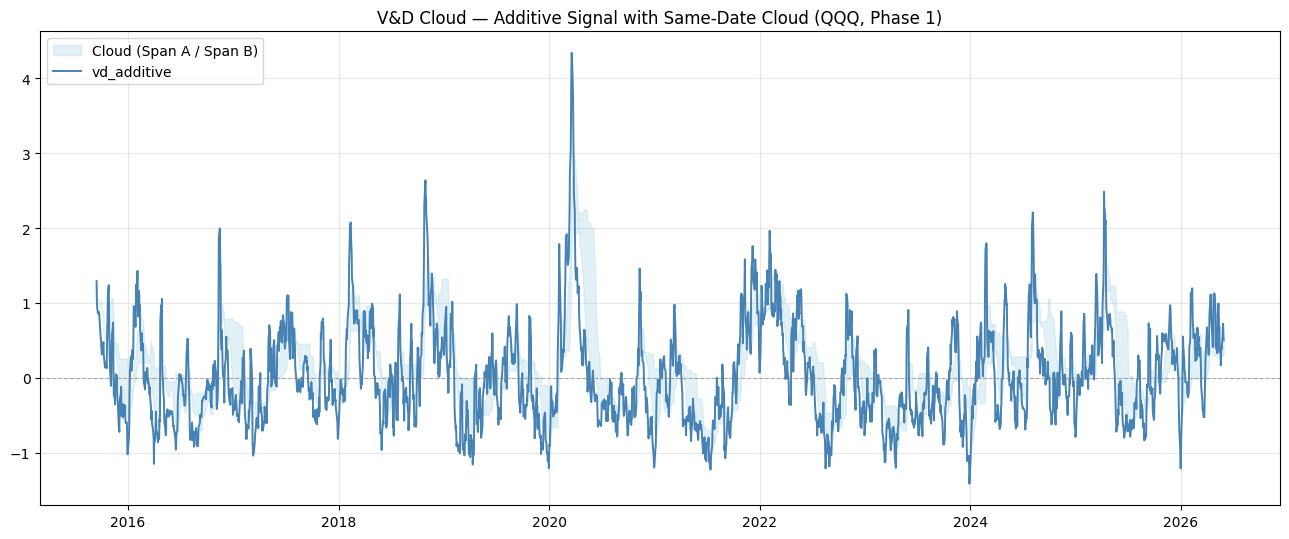

In [9]:
additive_cloud = build_variant_cloud(vd_additive, "additive")
penalty_cloud  = build_variant_cloud(vd_penalty, "penalty")

for name, frame in [("additive", additive_cloud), ("penalty", penalty_cloud)]:
    print(f"--- {name} regime distribution ---")
    print(frame["regime_state"].value_counts())
    print()

fig, ax = plt.subplots(figsize=(13, 5.5))
idx = additive_cloud.index
ax.fill_between(idx, additive_cloud["cloud_bottom"], additive_cloud["cloud_top"],
                 color="lightblue", alpha=0.35, label="Cloud (Span A / Span B)")
ax.plot(idx, additive_cloud["signal"], color="steelblue", linewidth=1.4, label="vd_additive")
ax.axhline(0, color="gray", linewidth=0.8, linestyle="--", alpha=0.6)
ax.set_title("V&D Cloud — Additive Signal with Same-Date Cloud (QQQ, Phase 1)")
ax.legend(loc="upper left"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 6. Forward-Return-by-Regime Analysis

For each regime label (`above_cloud`, `inside_cloud`, `below_cloud`), summarize QQQ and TQQQ
forward returns at 5/10/21/63-day horizons. Forward return at date *t* is the compounded return
from *t+1* through *t+h* — the same-day return at *t* is excluded so the label isn't peeking at
its own outcome.

TQQQ is a 3x daily-reset leveraged product with volatility decay; its forward returns reflect that
structural behavior and should not be read as a clean read on signal quality by themselves.

In [10]:
def calculate_forward_returns(return_series, horizons):
    forward = pd.DataFrame(index=return_series.index)
    for h in horizons:
        forward[f"fwd_{h}d"] = (
            (1 + return_series).shift(-1).rolling(window=h).apply(np.prod, raw=True).shift(-(h - 1)) - 1
        )
    return forward

def summarize_forward_returns_by_regime(validation_frame, asset_label, horizons):
    rows = []
    for h in horizons:
        col = f"fwd_{h}d"
        for regime, group in validation_frame.groupby("regime_state"):
            r = group[col].dropna()
            if r.empty:
                continue
            rows.append({
                "asset": asset_label, "horizon": h, "regime_state": regime,
                "sample_count": len(r), "mean_return": r.mean(), "median_return": r.median(),
                "win_rate": (r > 0).mean(), "std_return": r.std(),
            })
    return pd.DataFrame(rows)

qqq_fwd  = calculate_forward_returns(benchmark_returns, FORWARD_HORIZONS)
tqqq_fwd = calculate_forward_returns(overlay_returns, FORWARD_HORIZONS)

print(f"qqq_fwd shape : {qqq_fwd.shape}")
print(f"tqqq_fwd shape: {tqqq_fwd.shape}")

qqq_fwd shape : (2867, 4)
tqqq_fwd shape: (2867, 4)


In [11]:
validation_rows = []
for lens_name, cloud_frame in [("additive", additive_cloud), ("penalty", penalty_cloud)]:
    regime_col = cloud_frame[["regime_state"]]
    qqq_val  = regime_col.join(qqq_fwd, how="left")
    tqqq_val = regime_col.join(tqqq_fwd, how="left")
    qqq_summary  = summarize_forward_returns_by_regime(qqq_val, "QQQ", FORWARD_HORIZONS)
    tqqq_summary = summarize_forward_returns_by_regime(tqqq_val, "TQQQ", FORWARD_HORIZONS)
    qqq_summary["lens"] = lens_name
    tqqq_summary["lens"] = lens_name
    validation_rows += [qqq_summary, tqqq_summary]

validation_summary = pd.concat(validation_rows, ignore_index=True).sort_values(
    ["lens", "asset", "horizon", "regime_state"]).reset_index(drop=True)

validation_summary

,asset,horizon,regime_state,sample_count,mean_return,median_return,win_rate,std_return,lens
0,QQQ,5,above_cloud,809,0.002959,0.005384,0.588381,0.032599,additive
1,QQQ,5,below_cloud,1313,0.004589,0.006643,0.615385,0.026196,additive
2,QQQ,5,inside_cloud,566,0.004798,0.007668,0.625442,0.026430,additive
3,QQQ,10,above_cloud,809,0.006528,0.009971,0.605686,0.043462,additive
4,QQQ,10,below_cloud,1311,0.009475,0.013479,0.672006,0.036970,additive
5,QQQ,10,inside_cloud,563,0.007907,0.013305,0.658970,0.037461,additive
6,QQQ,21,above_cloud,805,0.017184,0.016630,0.642236,0.058832,additive
7,QQQ,21,below_cloud,1311,0.020146,0.027779,0.723112,0.053961,additive
8,QQQ,21,inside_cloud,556,0.011029,0.014191,0.645683,0.058062,additive
9,QQQ,63,above_cloud,785,0.049014,0.049066,0.756688,0.087512,additive


## 7. Regime Persistence and Stability

Do regimes behave like durable market "weather states," or do they flicker day to day? For each
lens, compute contiguous regime runs and summarize their duration. A regime that changes every
other day is much harder to trust diagnostically than one that holds for weeks.

In [12]:
def compute_regime_runs(regime_series, regime_name):
    regime_series = regime_series.dropna()
    run_id = regime_series.ne(regime_series.shift()).cumsum()
    runs = (
        pd.DataFrame({"date": regime_series.index, "regime_state": regime_series.values, "run_id": run_id.values})
        .groupby("run_id")
        .agg(regime_state=("regime_state", "first"), start_date=("date", "first"),
             end_date=("date", "last"), duration_days=("date", "count"))
        .reset_index(drop=True)
    )
    runs["regime_name"] = regime_name
    return runs

all_runs = pd.concat([
    compute_regime_runs(additive_cloud["regime_state"], "additive"),
    compute_regime_runs(penalty_cloud["regime_state"], "penalty"),
], ignore_index=True)

stability_summary = (
    all_runs.groupby(["regime_name", "regime_state"])["duration_days"]
    .agg(run_count="count", mean_duration="mean", median_duration="median")
    .reset_index()
)
stability_summary

,regime_name,regime_state,run_count,mean_duration,median_duration
0,additive,above_cloud,123,6.601626,5.0
1,additive,below_cloud,146,8.993151,6.0
2,additive,inside_cloud,200,2.840000,2.0
3,penalty,above_cloud,149,5.986577,5.0
4,penalty,below_cloud,157,7.777070,5.0
5,penalty,inside_cloud,236,2.457627,2.0


## 8. Robustness: HAC (Newey-West) Inference and Random-Label Permutation

Forward-return windows of 21 trading days overlap heavily (consecutive 21-day windows share ~20
of 21 observations), so naive t-statistics on regime-conditional means overstate confidence. Two
independent, more skeptical checks are applied:

- **HAC / Newey-West inference** — regress each regime state's forward return against the
  unconditional mean using OLS with a HAC covariance estimator (`maxlags=21`), which is robust to
  the autocorrelation the overlapping windows create.
- **Random-label permutation** — shuffle the regime labels 1,000 times (preserving the realized
  return path and the label distribution exactly) and compare the *observed* excess return to the
  distribution of excess returns under random shuffles. This tests whether the label carries more
  information than a randomly-assigned label with the same group sizes would.

Neither test proves predictive power on its own; they test different, complementary failure modes.

In [13]:
import math

try:
    import statsmodels.api as sm
    STATSMODELS_AVAILABLE = True
except ImportError:
    STATSMODELS_AVAILABLE = False

print("statsmodels available:", STATSMODELS_AVAILABLE)


def hac_mean_inference(return_series, benchmark_mean=0.0, maxlags=21):
    x = pd.Series(return_series).dropna()
    if len(x) < maxlags + 5 or not STATSMODELS_AVAILABLE:
        return {"hac_t_stat": np.nan, "hac_available": False}
    y = x - benchmark_mean
    X = np.ones((len(y), 1))
    model = sm.OLS(y.values, X).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})
    return {"hac_t_stat": model.tvalues[0], "hac_available": True}


def summarize_regime_inference(frame, return_col, hac_lags=21):
    uncond_mean = frame[return_col].dropna().mean()
    rows = []
    for regime_state, group in frame.dropna(subset=["regime_state", return_col]).groupby("regime_state"):
        r = group[return_col].dropna()
        simple_t = (r.mean() - uncond_mean) / (r.std(ddof=1) / math.sqrt(len(r))) if len(r) > 1 else np.nan
        hac = hac_mean_inference(r, benchmark_mean=uncond_mean, maxlags=hac_lags)
        rows.append({
            "regime_state": regime_state, "sample_count": len(r), "mean_return": r.mean(),
            "excess_vs_unconditional": r.mean() - uncond_mean,
            "simple_t_stat": simple_t, "hac_t_stat": hac["hac_t_stat"],
        })
    return pd.DataFrame(rows)

print("HAC inference helpers defined.")

statsmodels available: True
HAC inference helpers defined.


In [14]:
hac_rows = []
for lens_name, cloud_frame in [("additive", additive_cloud), ("penalty", penalty_cloud)]:
    joined = cloud_frame[["regime_state"]].join(qqq_fwd[["fwd_21d"]], how="left")
    summary = summarize_regime_inference(joined, return_col="fwd_21d", hac_lags=21)
    summary["lens"] = lens_name
    hac_rows.append(summary)

hac_summary = pd.concat(hac_rows, ignore_index=True)
hac_summary

,regime_state,sample_count,mean_return,excess_vs_unconditional,simple_t_stat,hac_t_stat,lens
0,above_cloud,805,0.017184,-0.000172,-0.083176,-0.029791,additive
1,below_cloud,1311,0.020146,0.002790,1.871806,0.587226,additive
2,inside_cloud,556,0.011029,-0.006328,-2.569854,-1.236118,additive
3,above_cloud,877,0.021576,0.004220,2.456566,0.893643,penalty
4,below_cloud,1219,0.012070,-0.005287,-3.056496,-0.984495,penalty
5,inside_cloud,576,0.022120,0.004763,2.084318,1.037822,penalty


In [15]:
def run_regime_label_permutation_test(frame, return_col, n_permutations=1000, random_seed=42):
    rng = np.random.default_rng(random_seed)
    temp = frame[["regime_state", return_col]].dropna()
    uncond_mean = temp[return_col].mean()

    observed = temp.groupby("regime_state")[return_col].mean() - uncond_mean

    labels = temp["regime_state"].to_numpy()
    values = temp[return_col].to_numpy()
    perm_excess = {state: [] for state in observed.index}

    for _ in range(n_permutations):
        shuffled = rng.permutation(labels)
        perm_frame = pd.DataFrame({"regime_state": shuffled, return_col: values})
        perm_means = perm_frame.groupby("regime_state")[return_col].mean() - uncond_mean
        for state in observed.index:
            if state in perm_means.index:
                perm_excess[state].append(perm_means.loc[state])

    rows = []
    for state, observed_excess in observed.items():
        dist = np.array(perm_excess[state])
        p_two_sided = float((np.abs(dist - dist.mean()) >= np.abs(observed_excess - dist.mean())).mean())
        rows.append({
            "regime_state": state, "observed_excess": observed_excess,
            "permutation_mean": dist.mean(), "permutation_std": dist.std(),
            "empirical_p_two_sided": p_two_sided,
        })
    return pd.DataFrame(rows)

print("Permutation test helper defined.")

Permutation test helper defined.


In [16]:
perm_rows = []
for lens_name, cloud_frame in [("additive", additive_cloud), ("penalty", penalty_cloud)]:
    joined = cloud_frame[["regime_state"]].join(qqq_fwd[["fwd_21d"]], how="left")
    result = run_regime_label_permutation_test(joined, return_col="fwd_21d", n_permutations=1000, random_seed=42)
    result["lens"] = lens_name
    perm_rows.append(result)

permutation_summary = pd.concat(perm_rows, ignore_index=True)
permutation_summary

,regime_state,observed_excess,permutation_mean,permutation_std,empirical_p_two_sided,lens
0,above_cloud,-0.000172,0.000043,0.001687,0.905,additive
1,below_cloud,0.002790,-0.000043,0.001139,0.008,additive
2,inside_cloud,-0.006328,0.000038,0.002125,0.004,additive
3,above_cloud,0.004220,-0.000001,0.001522,0.005,penalty
4,below_cloud,-0.005287,0.000025,0.001186,0.000,penalty
5,inside_cloud,0.004763,-0.000051,0.001988,0.018,penalty


## Phase 1 Verdict

Six layers of validation ran against the QQQ prototype: baseline challenge, conditional-bucket
tests, regime-stability diagnostics, persistence filters, HAC / Newey-West inference, and
random-label permutation testing.

**High-level result: the V&D Cloud survived as a coherent diagnostic framework, but not as a
statistically validated predictive model.**

What it earned:
- A coherent multi-lens regime grammar — additive and penalty measure genuinely different things.
- **Penalty above_cloud / below_cloud showed the cleanest separation** in the permutation test —
  the strongest surviving evidence in the whole Phase 1 build, and the closest thing to a
  "not-random-looking" result.
- **Additive inside_cloud read as a possible turbulence / unresolved-transition state** rather than
  a neutral middle ground — its excess return also looked unusual under permutation, but in the
  weak direction.
- Additive below_cloud showed a plausible cooling/stabilization read, though HAC support for it
  was weak.

What it did **not** earn:
- Predictive proof. HAC inference weakened the strongest-looking t-statistics from "supportive" to
  "directional at best" once overlapping-return autocorrelation was properly accounted for.
- Trading-rule status — no thresholds, position sizing, or transaction costs were ever modeled.
- Generalization beyond QQQ, a single, concentrated, mega-cap-heavy, growth-tilted universe.
- Out-of-sample validation of any kind.

**This is diagnostically coherent, not statistically confirmed as predictive.** The recommended
next step in the original research arc was to test the same grammar on a different universe —
which is exactly what `02_cross_market_validation_clean.ipynb` does.